In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="xk9ZBaXpmTeBAaTAVtRN")
project = rf.workspace("eiaroboflow").project("rock-paper-scissors-sxsw-mvkml")
version = project.version(1)
dataset = version.download("yolov11")


In [ ]:
!pip install ultralytics

In [8]:
from ultralytics import YOLO
# Model #
model=YOLO("yolo11m.pt")
# ----------------------------- #

In [9]:
# Train Model #
model.train(
    data="/content/rock-paper-scissors-1/data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    name="Rock_Paper_ScissorsYolo11_Final",
    patience=5,
    val=True, # The Model Train and Test in Valid Set
    # --------------------------------------------- #
    # Data Augmentations #
 # Geometric Augmentations
    degrees=15.0,
    translate=0.15,
    scale=0.5,
    shear=5.0,
    perspective=0.0005,

    # Flip Augmentations
    fliplr=0.5,
    flipud=0.0,

    # Color Augmentations (HSV)
    hsv_h=0.02,
    hsv_s=0.7,
    hsv_v=0.4,

    # Advanced Augmentations
    mosaic=1.0,
    mixup=0.15,
    copy_paste=0.1,
    close_mosaic=10,

    # Training
    optimizer="auto",
    seed=42,
    plots=True,
    save=True,
    save_period=5
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rock-paper-scissors-1/data.yaml, degrees=15.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Rock_Paper_ScissorsYolo11_Final, nbs=64, nms=Non

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c46b0a2c590>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [45]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/runs/detect/Rock_Paper_ScissorsYolo11_Final/weights/best.pt"
)

test_metrics = best_model.val(
    data="/content/rock-paper-scissors-1/data.yaml",
    split="test"
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,032,345 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1076.6±419.5 MB/s, size: 53.8 KB)
val: Scanning /content/rock-paper-scissors-1/test/labels.cache... 485 images, 200 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 485/485 70.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 2.5it/s 12.2s


Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor


                   all        485        321      0.898       0.93      0.952      0.677
                 Paper         98         98      0.902      0.888      0.935      0.638
                  Rock        104        119      0.914      0.941      0.958      0.682
              Scissors        101        104      0.877      0.961      0.964      0.712
Speed: 1.1ms preprocess, 18.5ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val-4


In [46]:
print("Per Class Metrics:")

for i, name in enumerate(model.names.values()):
    print(f"\nClass: {name}")
    print(f"Precision: {test_metrics.box.p[i]:.4f}")
    print(f"Recall: {test_metrics.box.r[i]:.4f}")
    print(f"mAP50: {test_metrics.box.ap50[i]:.4f}")
    print(f"mAP50-95: {test_metrics.box.ap[i].mean():.4f}")

Per Class Metrics:

Class: Paper
Precision: 0.9022
Recall: 0.8878
mAP50: 0.9347
mAP50-95: 0.6376

Class: Rock
Precision: 0.9143
Recall: 0.9412
mAP50: 0.9582
mAP50-95: 0.6816

Class: Scissors
Precision: 0.8771
Recall: 0.9611
mAP50: 0.9643
mAP50-95: 0.7125


In [47]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import os
from PIL import Image

In [48]:

def DrowingImages(image, box, label, color_samples):

    # Convert PIL Image to NumPy array
    image_with_boxes = np.array(image).copy()

    # Get bounding box coordinates
    xmin, ymin, xmax, ymax = box

    # Select random color
    color = random.choice(color_samples)

    # Draw rectangle
    cv2.rectangle(
        image_with_boxes,
        (xmin, ymin),
        (xmax, ymax),
        color,
        2
    )

    # Draw class name
    cv2.putText(
        image_with_boxes,
        label,
        (xmin, max(ymin - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        color,
        2
    )

    return image_with_boxes


In [49]:
best_model = YOLO(
    "/content/runs/detect/Rock_Paper_ScissorsYolo11_Final/weights/best.pt"
)
Test_Image_dir="/content/rock-paper-scissors-1/test/images"


0: 640x640 1 Paper, 39.9ms
Speed: 2.6ms preprocess, 39.9ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

0: 384x640 1 Paper, 25.6ms
Speed: 1.6ms preprocess, 25.6ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 24.3ms
Speed: 1.7ms preprocess, 24.3ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 24.3ms
Speed: 1.9ms preprocess, 24.3ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)

0: 480x640 1 Paper, 31.0ms
Speed: 2.1ms preprocess, 31.0ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 (no detections), 28.3ms
Speed: 0.9ms preprocess, 28.3ms inference, 0.7ms postprocess per image at shape (1, 3, 480, 640)

0: 384x640 1 Paper, 1 Scissors, 20.5ms
Speed: 2.3ms preprocess, 20.5ms inference, 2.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 Scissorss, 19.4ms
Speed: 1.5ms preprocess, 19.4ms inference, 1.5ms postproc

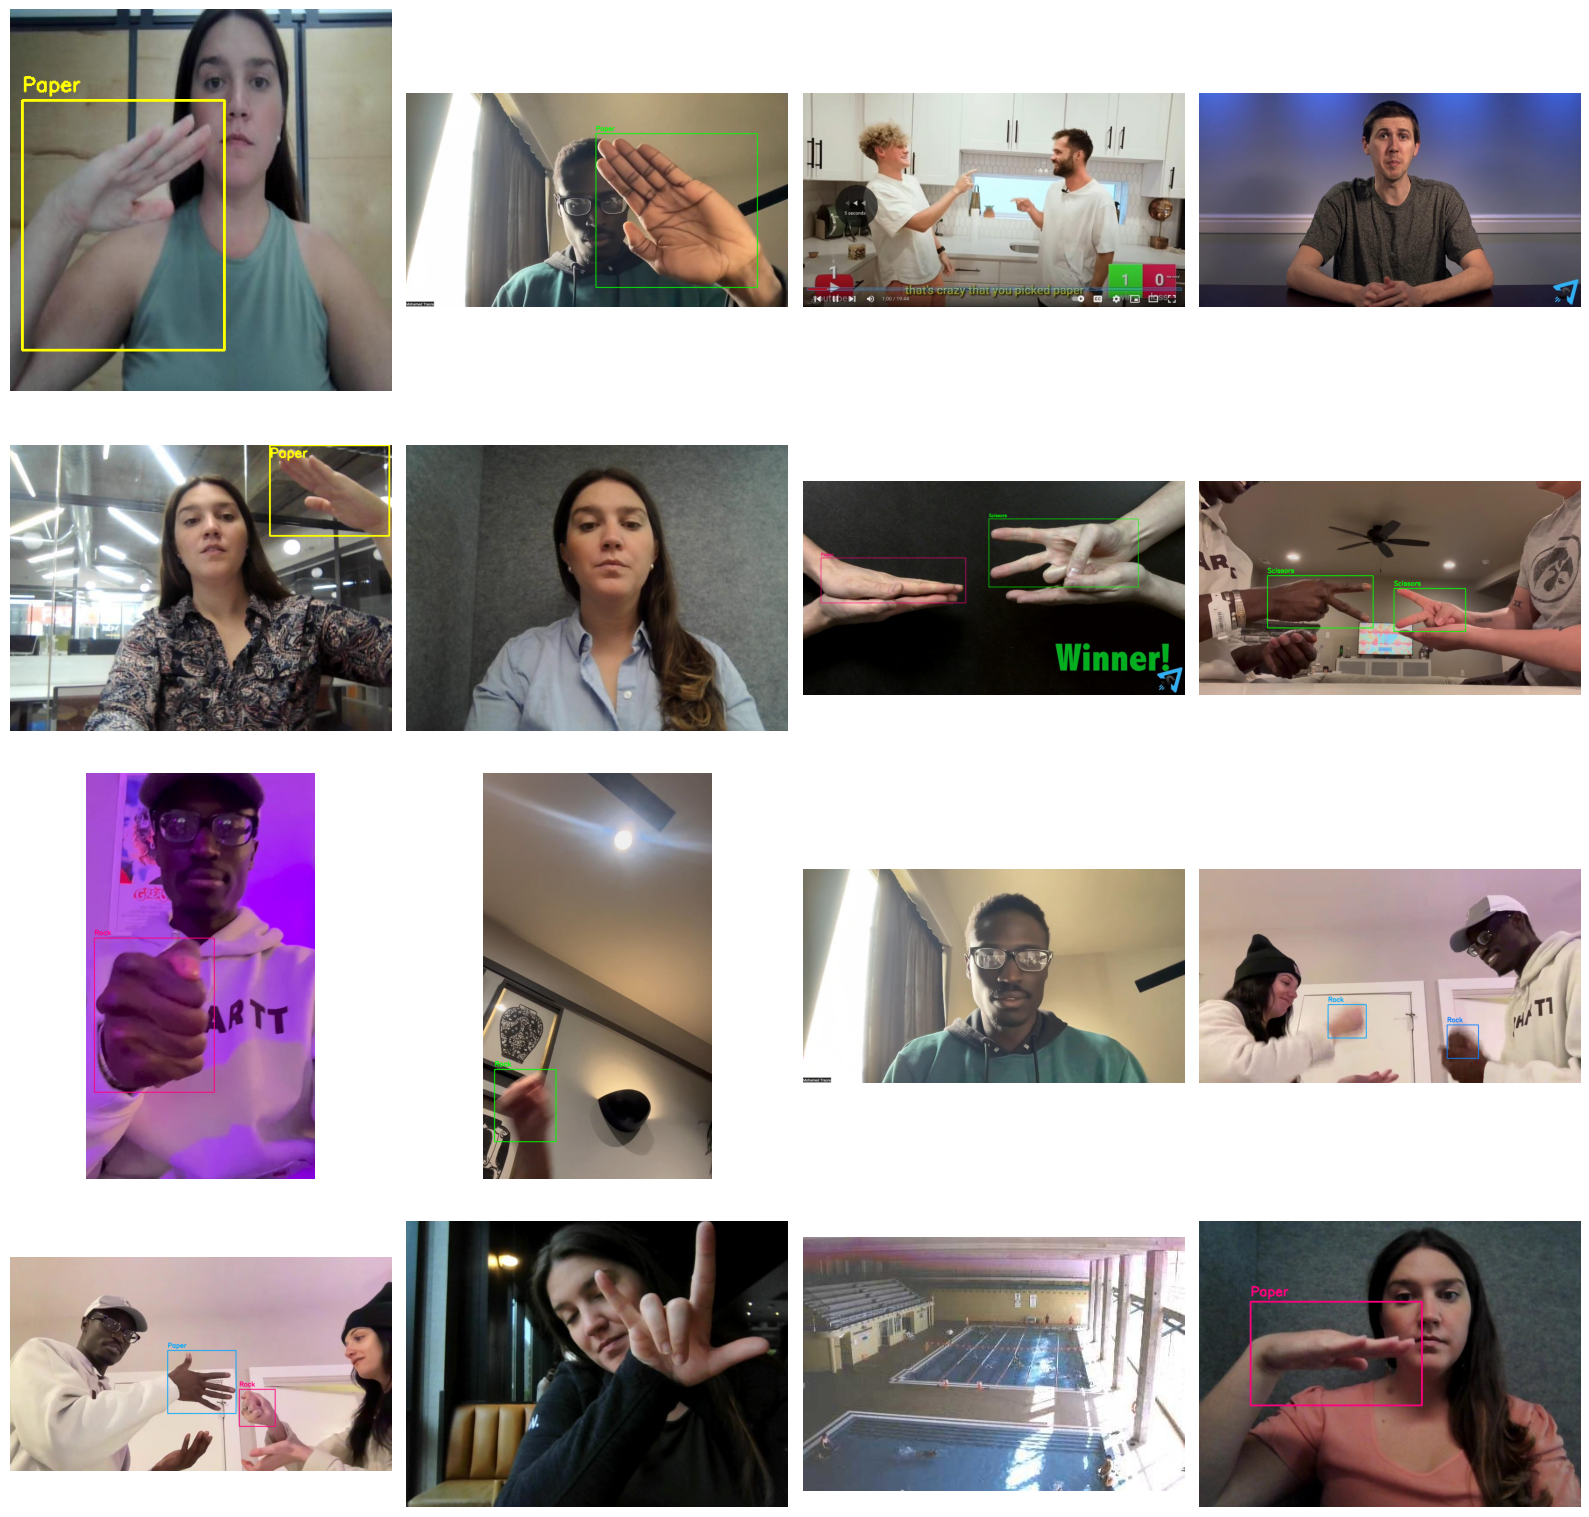

In [50]:

color_sample = [
    (12, 128, 255),
    (255, 0, 127),
    (0, 255, 0),
    (255, 255, 0),
    (0, 165, 255)
]

# Get test images
image_path_dir = os.listdir(Test_Image_dir)

# Create 4x4 plot
fig, ax = plt.subplots(4, 4, figsize=(16, 16))
ax = ax.ravel()

# Select 16 random images
selected_images = random.sample(image_path_dir, min(16, len(image_path_dir)))

for idx, image_name in enumerate(selected_images):

    image_path = os.path.join(Test_Image_dir, image_name)
    image = Image.open(image_path).convert("RGB")

    # Inference
    results = model(image)[0]

    # Draw Bounding Boxes
    for box in results.boxes:

        xyxy = list(map(int, box.xyxy[0].tolist()))

        cls_id = int(box.cls[0])
        label = model.names[cls_id]

        image = DrowingImages(
            image=image,
            box=xyxy,
            label=label,
            color_samples=color_sample
        )

    # Convert image to NumPy array
    image = np.array(image)

    # Plot
    ax[idx].imshow(image)
    ax[idx].axis("off")

# Hide unused axes if fewer than 16 images
for idx in range(len(selected_images), 16):
    ax[idx].axis("off")

plt.tight_layout()
plt.show()


In [51]:
from google.colab import files

files.download(
    "/content/runs/detect/Rock_Paper_ScissorsYolo11_Final/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import ultralytics
print(f"Version :{ultralytics.__version__}")

Version :8.4.216
